# Arquitectura multiagente con LangGraph


Este notebook resuelve el mismo proyecto que la versión «desde cero», pero con **LangGraph**: el flujo entre agentes se declara como un **grafo de estados** (nodos, aristas y un estado compartido) en lugar de programarse a mano. El objetivo es el mismo: diseñar, implementar y **medir** calidad, costo, latencia, robustez y costo de coordinación.

**Caso guía.** La *Tostaduría Samán* (empresa **ficticia** de Cali) debe decidir su próxima inversión. Los agentes consultan su base de conocimiento interna y responden preguntas de negocio citando las fuentes.

**Cómo correrlo.**

- La clave de **OpenRouter** se lee del archivo `.env` (sección 0).
- Sin clave, el notebook corre en **modo simulado**: un modelo de chat falso, compatible con LangChain, imita las respuestas para que el grafo, las trazas y las métricas funcionen sin gastar crédito. Sus puntajes de calidad **no** describen a ningún modelo real.

| Sección | Contenido |
|---|---|
| 0 | Configuración: `.env`, modelos y precios |
| 1 | Base de conocimiento y herramienta (`@tool`) |
| 2 | Modelos de chat y trazas con *callbacks* |
| 3 | Un agente ReAct como grafo: `StateGraph` + `ToolNode` |
| 4 | Baseline: agente único |
| 5 | Grafo multiagente: orquestador, `Send` en paralelo y crítico |
| 6 | Observabilidad |
| 7 | Evaluación |
| 8 | Experimento comparativo |
| 9 | Optimización y router |
| 10 | Ejercicios |

## 0. Configuración

### 0.1 Dependencias

In [1]:
# Dependencias gestionadas con uv; ejecutar `uv sync` desde la carpeta del proyecto.

### 0.2 El archivo `.env`

En la misma carpeta del notebook se crea un archivo llamado `.env` con este contenido:

```
OPENROUTER_API_KEY=sk-or-v1-...
```

`load_dotenv()` lo carga como variables de entorno. Si el proyecto está en git, `.env` debe ir en `.gitignore` para que la clave nunca se suba al repositorio.

Opcional: para ver cada ejecución del grafo en LangSmith, se agregan al mismo `.env` las líneas `LANGSMITH_TRACING=true` y `LANGSMITH_API_KEY=...`.

In [2]:
import os, json, time, asyncio, random, re, unicodedata, uuid, operator
from collections import defaultdict
from dataclasses import dataclass
from typing import Annotated, TypedDict
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, ValidationError
from dotenv import load_dotenv, find_dotenv

ruta_env = find_dotenv(usecwd=True)          # busca .env en la carpeta actual y en las superiores
load_dotenv(ruta_env, override=True)
OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY", "").strip()
MODO_SIMULADO = not OPENROUTER_API_KEY

# --- Modelos por rol (identificadores de OpenRouter) ---------------------
MODELOS = {
    "trabajador": "deepseek/deepseek-v4.1-flash",
    "orquestador": "deepseek/deepseek-v4.1-flash",
    "fuerte": "deepseek/deepseek-v4-pro",   # DeepSeek más capaz (y más caro)
    "juez": "anthropic/claude-haiku-5.5",   # evaluador de otra familia: menos sesgo
}

# --- Precios de referencia: USD por millón de tokens (entrada, salida) ---
# Referencia de octubre de 2026; en modo real se reemplazan por los precios en vivo.
PRECIOS = {
    "deepseek/deepseek-v4.1-flash": (0.028, 0.12),
    "openai/gpt-6-luna": (0.10, 0.50),
    "anthropic/claude-haiku-5.5": (0.10, 0.50),
    "deepseek/deepseek-v4-pro": (1.6, 3.2),
}

TOPE_USD_POR_TAREA = 0.05   # freno de emergencia por tarea
TAREAS_SIMULTANEAS = 3      # tareas del dataset en paralelo (evita límites de tasa)
REPETICIONES = 3            # corridas por pregunta: las respuestas varían y una sola puede engañar
random.seed(7)

print(".env:", ruta_env or "no encontrado")
print("Modo:", "SIMULADO (sin costo)" if MODO_SIMULADO else "OpenRouter (costo real)")

.env: /home/jmrojas/Documents/universidad/7semestre/inteligencia_artificial/Reto 3/multiagente/.env
Modo: OpenRouter (costo real)


In [3]:
# Verifica los identificadores de modelo y actualiza los precios con los valores en vivo.
if not MODO_SIMULADO:
    import httpx
    catalogo = {m["id"]: m for m in httpx.get("https://openrouter.ai/api/v1/models", timeout=30).json()["data"]}
    for rol, slug in MODELOS.items():
        m = catalogo.get(slug)
        if m:
            p_in, p_out = float(m["pricing"]["prompt"]) * 1e6, float(m["pricing"]["completion"]) * 1e6
            PRECIOS[slug] = (p_in, p_out)
            print(f"OK  {rol:<12} {slug:<34} entrada {p_in:.3f}  salida {p_out:.3f} USD/M")
        else:
            familia = slug.split("/")[1].split("-")[0]
            print(f"NO ENCONTRADO {rol}: {slug}. Parecidos:", [k for k in catalogo if familia in k][:6])
else:
    print("Modo simulado: se usan los precios de referencia de la tabla PRECIOS.")

OK  trabajador   deepseek/deepseek-v4.1-flash       entrada 0.045  salida 0.500 USD/M
OK  orquestador  deepseek/deepseek-v4.1-flash       entrada 0.045  salida 0.500 USD/M
OK  fuerte       deepseek/deepseek-v4-pro           entrada 1.600  salida 3.200 USD/M
OK  juez         anthropic/claude-haiku-5.5         entrada 0.100  salida 0.500 USD/M


## 1. Base de conocimiento y herramienta

El corpus son once documentos ficticios. En LangChain una herramienta se declara con el decorador `@tool`: el nombre, la *docstring* y los tipos de los argumentos se convierten automáticamente en la descripción que recibe el modelo.

La herramienta recibe además la `config` de la ejecución (LangChain la inyecta sola y el modelo no la ve). Con ella se registra qué documentos consultó cada tarea, para medir después el trabajo repetido.

In [4]:
CORPUS = [
    {"id": "D1", "titulo": "Perfil de la empresa",
     "texto": "Tostaduría Samán fue fundada en 2018 en Cali, tiene 14 empleados y tuesta café de Huila y Cauca. Opera una tienda en el barrio San Antonio y vende por tres canales: tienda, clientes B2B (cafeterías y hoteles) y domicilios por WhatsApp."},
    {"id": "D2", "titulo": "Ventas 2025 por canal",
     "texto": "Ingresos 2025: COP 2.140 millones. Participación: tienda 38 %, B2B 47 %, domicilios por WhatsApp 15 %. Crecimiento frente a 2024: tienda 4 %, B2B 18 %, domicilios 41 %."},
    {"id": "D3", "titulo": "Costos y márgenes",
     "texto": "Margen bruto por canal: tienda 58 %, B2B 31 %, domicilios 44 % después del costo de envío. El café verde representa el 46 % del costo de producción y su precio subió 22 % en 2025."},
    {"id": "D4", "titulo": "Capacidad de la planta",
     "texto": "La tostadora procesa 15 kg por lote y trabaja en promedio al 72 % de su capacidad en un turno. Un segundo turno aumentaría la capacidad 60 %. Una tostadora nueva de 30 kg cuesta COP 310 millones."},
    {"id": "D5", "titulo": "Encuesta de clientes (marzo 2026)",
     "texto": "Encuesta a 412 clientes: 63 % compraría una suscripción mensual de café. La principal queja son los tiempos de entrega de domicilios, 3,2 días en promedio. NPS de 54."},
    {"id": "D6", "titulo": "Competencia",
     "texto": "Hay tres tostadurías de especialidad competidoras en Cali. Dos ya venden en línea con suscripción. Su precio promedio por bolsa de 250 g es 8 % más alto que el de Samán."},
    {"id": "D7", "titulo": "Opción A: tienda online con suscripciones",
     "texto": "Inversión de COP 95 millones en plataforma, fotografía y logística. Punto de equilibrio estimado en 14 meses. Requiere contratar una persona de atención al cliente."},
    {"id": "D8", "titulo": "Opción B: segunda tienda física",
     "texto": "Segunda tienda en el norte de Cali. Inversión de COP 420 millones, arriendo mensual de COP 11 millones. Punto de equilibrio estimado en 30 meses."},
    {"id": "D9", "titulo": "Opción C: exportación a Chile",
     "texto": "Un distribuidor en Chile exige un pedido mínimo de 1,2 toneladas al año con margen de 24 %. Requiere certificación sanitaria (6 meses de trámite) y una inversión de COP 60 millones."},
    {"id": "D10", "titulo": "Riesgos",
     "texto": "Tres clientes B2B concentran el 29 % de las ventas. La rotación anual de baristas es de 35 %. La volatilidad del precio del café verde afecta sobre todo al canal B2B, que tiene precios fijos por contrato anual."},
    {"id": "D11", "titulo": "Situación financiera",
     "texto": "Caja disponible: COP 380 millones. Crédito preaprobado por COP 250 millones al 17 % efectivo anual. La junta directiva exige recuperar cualquier inversión en menos de 24 meses."},
]

STOP = set("de la el los las un una y o en a por para con que se del al es su sus como mas más qué cual cuál hay debe debería puede si sin lo le ante sobre entre".split())

def normalizar(texto: str) -> str:
    texto = unicodedata.normalize("NFD", texto.lower())
    return "".join(c for c in texto if unicodedata.category(c) != "Mn")

def terminos(texto: str) -> set[str]:
    return {t for t in re.findall(r"[a-z0-9]+", normalizar(texto)) if t not in STOP and len(t) > 2}

def buscar_docs(consulta: str, k: int = 3) -> list[dict]:
    q = terminos(consulta)
    puntuados = [(len(q & terminos(d["titulo"] + " " + d["texto"])), d) for d in CORPUS]
    puntuados = [p for p in puntuados if p[0] > 0]
    puntuados.sort(key=lambda p: -p[0])
    return [d for _, d in puntuados[:k]]

In [5]:
from langchain_core.tools import tool
from langchain_core.runnables import RunnableConfig

DOCS_POR_TAREA: dict[str, list[str]] = defaultdict(list)

@tool
async def buscar_en_corpus(consulta: str, config: RunnableConfig) -> str:
    """Busca en la base de conocimiento interna de Tostaduría Samán. Devuelve hasta 3 documentos con id, título y texto."""
    docs = buscar_docs(consulta)
    tarea = (config.get("metadata") or {}).get("tarea")
    if tarea:
        DOCS_POR_TAREA[tarea] += [d["id"] for d in docs]
    return json.dumps(docs, ensure_ascii=False)

HERRAMIENTAS = [buscar_en_corpus]
print(buscar_en_corpus.name, "→", buscar_en_corpus.args)   # lo que ve el modelo: solo 'consulta'

buscar_en_corpus → {'consulta': {'title': 'Consulta', 'type': 'string'}}


## 2. Modelos de chat y trazas

### 2.1 Fábrica de modelos

`ChatOpenAI` funciona con OpenRouter porque su API es compatible con la de OpenAI: basta con cambiar `base_url`. Cada modelo se crea **por agente**, con `with_config(metadata=...)`, para que las trazas sepan qué agente hizo cada llamada.

En modo simulado se usa `ChatSimulado`, un modelo falso que hereda de `BaseChatModel`: para LangGraph es indistinguible de uno real (soporta herramientas, mensajes y conteo de tokens).

In [6]:
from langchain_openai import ChatOpenAI
from langchain_core.language_models import BaseChatModel
from langchain_core.outputs import ChatResult, ChatGeneration
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.utils.function_calling import convert_to_openai_tool

def costo_estimado(modelo: str, t_in: int, t_out: int) -> float:
    p_in, p_out = PRECIOS.get(modelo, (0.0, 0.0))
    return (t_in * p_in + t_out * p_out) / 1e6

def texto(mensaje) -> str:
    """Contenido de un mensaje como texto (algunos proveedores devuelven una lista de bloques)."""
    c = mensaje.content
    if isinstance(c, list):
        return "".join(b.get("text", "") if isinstance(b, dict) else str(b) for b in c)
    return c or ""

def crear_llm(modelo: str, agente: str, herramientas=None, json_mode=False, max_tokens=800, tool_choice=None):
    if MODO_SIMULADO:
        llm = ChatSimulado(modelo=modelo, rol=agente.split("_")[0])
    else:
        llm = ChatOpenAI(model=modelo, base_url="https://openrouter.ai/api/v1", api_key=OPENROUTER_API_KEY,
                         temperature=0.2, max_tokens=max_tokens, max_retries=2, timeout=90,
                         extra_body={"usage": {"include": True},             # pide a OpenRouter el costo real
                                     "reasoning": {"enabled": False}},   # sin razonamiento: no consume max_tokens
                         default_headers={"X-Title": "Clase arquitectura multiagente - Icesi"})
    if herramientas:
        llm = llm.bind_tools(herramientas, **({"tool_choice": tool_choice} if tool_choice else {}))
    elif json_mode:
        llm = llm.bind(response_format={"type": "json_object"})
    return llm.with_config(metadata={"agente": agente, "modelo": modelo})

### 2.2 El simulador

Solo se usa sin clave. Imita cada rol con reglas simples (busca, copia los documentos encontrados, arma JSON) y estima tokens como *caracteres / 4*. Se puede saltar en clase.

In [7]:
def _tokens(t: str) -> int:
    return max(1, len(t) // 4)

class ChatSimulado(BaseChatModel):
    modelo: str
    rol: str

    @property
    def _llm_type(self) -> str:
        return "simulado"

    def bind_tools(self, tools, tool_choice=None, **kwargs):
        return self.bind(tools=[convert_to_openai_tool(t) for t in tools], tool_choice=tool_choice, **kwargs)

    def _responder(self, messages, tools=None, tool_choice=None, **_) -> AIMessage:
        rol = self.rol
        sistema = texto(messages[0]) if isinstance(messages[0], SystemMessage) else ""
        usuario = next(texto(m) for m in reversed(messages) if isinstance(m, HumanMessage))
        resultados = [json.loads(m.content) for m in messages if isinstance(m, ToolMessage)]
        docs = list({d["id"]: d for lote in resultados if isinstance(lote, list) for d in lote}.values())
        tool_calls, salida = [], ""
        busquedas_max = 2 if rol == "unico" else 1

        if tools and tool_choice != "none" and len(resultados) < busquedas_max:
            consulta = usuario if not resultados else usuario + " costos riesgos financiación"
            tool_calls = [{"name": "buscar_en_corpus", "args": {"consulta": consulta[:300]},
                           "id": f"call_{uuid.uuid4().hex[:8]}", "type": "tool_call"}]
        elif rol in ("investigador", "unico"):
            m = re.search(r"máximo (\d+) palabras", sistema)
            limite = int(m.group(1)) if m else 200
            por_doc = max(12, limite // max(1, len(docs)))
            salida = " ".join(" ".join(d["texto"].split()[:por_doc]) + f" [{d['id']}]" for d in docs[:4])
        elif rol == "orquestador":
            n = int(re.search(r"máximo (\d+)", sistema).group(1))
            base = ["Ventas, márgenes y clientes", "Costos, capacidad e inversiones",
                    "Riesgos, competencia y financiación", "Encuesta y demanda"]
            salida = json.dumps({"subtareas": [f"{b} relevantes para: {usuario}" for b in base[:n]]}, ensure_ascii=False)
        elif rol == "router":
            compleja = len(terminos(usuario)) > 7 or " y " in usuario
            salida = json.dumps({"complejidad": "compleja" if compleja else "simple"})
        elif rol == "redactor":
            notas = usuario.split("Notas:")[-1].split("Borrador anterior:")[0]
            notas = "\n".join(l for l in notas.splitlines() if not l.startswith("###"))
            frases = [f.strip() for f in re.split(r"(?<=\])\s+", notas) if "[" in f]
            salida = "Recomendación basada en la evidencia: " + " ".join(dict.fromkeys(frases))[:1600]
        elif rol == "critico":
            citas = len(re.findall(r"\[D\d+\]", usuario.split("Respuesta propuesta:")[-1]))
            aprobado = citas >= 3 and random.random() > 0.35
            salida = json.dumps({"aprobado": aprobado, "puntaje": 4 if aprobado else 2,
                                 "comentarios": "Bien sustentada." if aprobado else "Falta una recomendación explícita y más cifras citadas."})
        elif rol == "juez":
            puntos = json.loads(re.search(r"<puntos>(.*?)</puntos>", usuario, re.S).group(1))
            respuesta = normalizar(re.search(r"<respuesta>(.*?)</respuesta>", usuario, re.S).group(1))
            salida = json.dumps({"puntos_presentes": [normalizar(p["termino"]) in respuesta for p in puntos],
                                 "fidelidad": 5 if len(re.findall(r"\[d\d+\]", respuesta)) >= 2 else 3,
                                 "claridad": 4 if len(respuesta.split()) <= 260 else 3, "justificacion": "simulado"})
        t_in = sum(_tokens(texto(m)) for m in messages) + (150 if tools else 0)
        t_out = _tokens(salida) + 20 * len(tool_calls)
        return AIMessage(content=salida, tool_calls=tool_calls,
                         usage_metadata={"input_tokens": t_in, "output_tokens": t_out, "total_tokens": t_in + t_out})

    def _generate(self, messages, stop=None, run_manager=None, **kwargs) -> ChatResult:
        return ChatResult(generations=[ChatGeneration(message=self._responder(messages, **kwargs))])

    async def _agenerate(self, messages, stop=None, run_manager=None, **kwargs) -> ChatResult:
        msg = self._responder(messages, **kwargs)
        await asyncio.sleep(0.03 + msg.usage_metadata["output_tokens"] * 0.0004)   # latencia simulada
        return ChatResult(generations=[ChatGeneration(message=msg)])

### 2.3 Trazas con *callbacks*

En LangChain la forma estándar de observar las llamadas es un **callback handler**: recibe un evento al empezar y al terminar cada llamada al modelo. `Trazador` guarda una fila por llamada (agente, modelo, tokens, costo, latencia) y aplica el **tope de gasto por tarea**: si una tarea ya lo superó, la siguiente llamada se cancela.

OpenRouter devuelve el costo real en `token_usage.cost`; si no llega, se estima:

$$\text{costo} = \frac{\text{tokens de entrada} \times p_{\text{entrada}} + \text{tokens de salida} \times p_{\text{salida}}}{10^6}$$

In [8]:
from langchain_core.callbacks import AsyncCallbackHandler

class PresupuestoExcedido(Exception):
    pass

class Trazador(AsyncCallbackHandler):
    raise_error = True   # deja pasar la excepción del tope de gasto

    def __init__(self):
        self.trazas: list[dict] = []
        self.costo_por_tarea: dict[str, float] = defaultdict(float)
        self._abiertas: dict = {}

    async def on_chat_model_start(self, serialized, messages, *, run_id, metadata=None, **kwargs):
        md = metadata or {}
        tarea = md.get("tarea")
        if tarea and self.costo_por_tarea[tarea] > md.get("tope_usd", float("inf")):
            raise PresupuestoExcedido(f"La tarea {tarea} superó el tope de USD {md['tope_usd']}")
        self._abiertas[run_id] = (time.perf_counter(), md)

    async def on_llm_end(self, response, *, run_id, **kwargs):
        t0, md = self._abiertas.pop(run_id, (time.perf_counter(), {}))
        msg = response.generations[0][0].message
        u = getattr(msg, "usage_metadata", None) or {}
        t_in, t_out = u.get("input_tokens", 0), u.get("output_tokens", 0)
        cache = (u.get("input_token_details") or {}).get("cache_read", 0) or 0
        uso = (msg.response_metadata or {}).get("token_usage") or (response.llm_output or {}).get("token_usage") or {}
        modelo = md.get("modelo", "")
        costo = uso.get("cost")
        if costo is None:
            costo = costo_estimado(modelo, t_in, t_out)
        self._registrar(md, t0, modelo, t_in, t_out, cache, float(costo), len(getattr(msg, "tool_calls", []) or []), None)

    async def on_llm_error(self, error, *, run_id, **kwargs):
        t0, md = self._abiertas.pop(run_id, (time.perf_counter(), {}))
        self._registrar(md, t0, md.get("modelo", ""), 0, 0, 0, 0.0, 0, repr(error)[:200])

    def _registrar(self, md, t0, modelo, t_in, t_out, cache, costo, n_tools, error):
        t1 = time.perf_counter()
        agente = md.get("agente", "?")
        self.trazas.append({"tarea": md.get("tarea"), "config": md.get("config"), "agente": agente,
                            "rol": agente.split("_")[0], "modelo": modelo, "inicio": t0, "fin": t1,
                            "latencia_s": t1 - t0, "tokens_entrada": t_in, "tokens_salida": t_out,
                            "tokens_cache": cache, "costo_usd": costo, "tool_calls": n_tools, "error": error})
        if md.get("tarea"):
            self.costo_por_tarea[md["tarea"]] += costo

TRAZADOR = Trazador()

def trazas_df() -> pd.DataFrame:
    return pd.DataFrame(TRAZADOR.trazas)

## 3. Un agente ReAct como grafo

Un agente es **modelo + instrucciones + herramientas + memoria + criterio de parada**. En LangGraph se expresa como un grafo de dos nodos:

- `modelo`: el LLM decide si responde o pide una herramienta.
- `herramientas`: un `ToolNode` ejecuta las herramientas pedidas.

La arista condicional `tools_condition` cierra el ciclo pensar → actuar → observar. El **estado** (`MessagesState`) es la memoria: la lista de mensajes, a la que cada nodo agrega los suyos. El criterio de parada es `max_pasos`: al llegarse, el modelo debe responder sin herramientas.

LangGraph trae `create_react_agent`, que hace lo mismo en una línea; aquí se construye a mano para ver cada pieza.

In [9]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Send

CIERRE = "Entregar ahora la respuesta final con la información disponible, sin usar más herramientas."

def construir_agente_react(agente: str, modelo: str, instrucciones: str, max_pasos: int = 4):
    llm = crear_llm(modelo, agente, herramientas=HERRAMIENTAS)
    llm_cierre = crear_llm(modelo, agente, herramientas=HERRAMIENTAS, tool_choice="none")

    async def nodo_modelo(state: MessagesState, config: RunnableConfig):
        mensajes = [SystemMessage(instrucciones)] + state["messages"]
        pasos = sum(isinstance(m, AIMessage) for m in state["messages"])
        if pasos >= max_pasos:                       # criterio de parada
            return {"messages": [await llm_cierre.ainvoke(mensajes + [HumanMessage(CIERRE)], config)]}
        return {"messages": [await llm.ainvoke(mensajes, config)]}

    g = StateGraph(MessagesState)
    g.add_node("modelo", nodo_modelo)
    g.add_node("herramientas", ToolNode(HERRAMIENTAS))
    g.add_edge(START, "modelo")
    g.add_conditional_edges("modelo", tools_condition, {"tools": "herramientas", END: END})
    g.add_edge("herramientas", "modelo")
    return g.compile(name=agente)

def mostrar_grafo(grafo, xray: bool = False):
    """Dibuja el grafo. Si no hay internet para renderizar la imagen, imprime el código Mermaid."""
    from IPython.display import Image, display
    try:
        display(Image(grafo.get_graph(xray=xray).draw_mermaid_png()))
    except Exception:
        print(grafo.get_graph(xray=xray).draw_mermaid())

## 4. Baseline: agente único

Antes de diseñar varios agentes se construye y se mide **un solo agente** con todas las herramientas. La versión multiagente solo se justifica si mejora la calidad lo suficiente para pagar su costo extra.

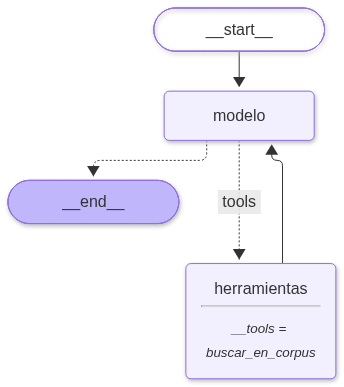

In [10]:
@dataclass
class Config:
    nombre: str
    arquitectura: str                      # "unico" | "multi" | "router"
    modelo_trabajador: str = MODELOS["trabajador"]
    modelo_orquestador: str = MODELOS["orquestador"]
    modelo_redactor: str = MODELOS["trabajador"]
    max_subtareas: int = 3
    max_rondas_critico: int = 2
    palabras_resumen: int = 150
    tope_usd: float = TOPE_USD_POR_TAREA

INSTR_UNICO = """Eres analista de negocios de Tostaduría Samán.
Usa la herramienta buscar_en_corpus las veces que necesites para reunir evidencia.
Responde en español en máximo 200 palabras, con una recomendación clara.
Cita cada dato con el id del documento entre corchetes, por ejemplo [D2].
No inventes cifras: usa solo lo que devuelva la herramienta."""
def construir_grafo_unico(cfg: Config):
    return construir_agente_react("unico", cfg.modelo_trabajador, INSTR_UNICO, max_pasos=4)

CFG_UNICO = Config("A · agente único", "unico")
grafo_unico = construir_grafo_unico(CFG_UNICO)
mostrar_grafo(grafo_unico)

Cada pregunta se ejecuta como una **tarea** con identificador propio. El identificador, la configuración y el tope de gasto viajan en la `metadata` de la ejecución: LangGraph la propaga a todos los nodos, modelos y herramientas, y así el `Trazador` sabe a qué tarea pertenece cada llamada.

Para que todas las arquitecturas se ejecuten igual, cada una declara cómo se arma su entrada y cómo se lee su salida.

In [11]:
ENTRADA = {"unico": lambda p: {"messages": [HumanMessage(p)]},
           "multi": lambda p: {"pregunta": p},
           "router": lambda p: {"pregunta": p}}
SALIDA = {"unico": lambda s: texto(s["messages"][-1]),
          "multi": lambda s: s["borrador"],
          "router": lambda s: s["respuesta"]}
CONSTRUCTORES = {"unico": construir_grafo_unico}   # se completa en las secciones 5 y 9
_GRAFOS: dict[str, object] = {}

def grafo_de(cfg: Config):
    if cfg.nombre not in _GRAFOS:
        _GRAFOS[cfg.nombre] = CONSTRUCTORES[cfg.arquitectura](cfg)
    return _GRAFOS[cfg.nombre]

def config_tarea(cfg: Config, tarea: str) -> dict:
    return {"callbacks": [TRAZADOR], "recursion_limit": 60,
            "metadata": {"tarea": tarea, "config": cfg.nombre, "tope_usd": cfg.tope_usd}}

async def ejecutar_tarea(cfg: Config, pregunta: str) -> dict:
    tarea = uuid.uuid4().hex[:8]
    t0 = time.perf_counter()
    try:
        estado = await grafo_de(cfg).ainvoke(ENTRADA[cfg.arquitectura](pregunta), config_tarea(cfg, tarea))
        respuesta, exito, error = SALIDA[cfg.arquitectura](estado), True, None
    except Exception as e:
        respuesta, exito, error = "", False, repr(e)[:200]
    return {"tarea": tarea, "config": cfg.nombre, "pregunta": pregunta, "respuesta": respuesta, "exito": exito,
            "error": error, "latencia_s": time.perf_counter() - t0,
            "costo_usd": TRAZADOR.costo_por_tarea.get(tarea, 0.0), "docs": DOCS_POR_TAREA.get(tarea, [])}

PREGUNTA_DEMO = "¿Qué opción de expansión conviene más si la junta exige recuperar la inversión en menos de 24 meses?"
r_unico = await ejecutar_tarea(CFG_UNICO, PREGUNTA_DEMO)
print(r_unico["respuesta"], "\n")
print(f"Costo: USD {r_unico['costo_usd']:.5f} · latencia {r_unico['latencia_s']:.2f} s · éxito {r_unico['exito']}")

**Recomendación: Opción A (tienda online con suscripciones).**

Con el requisito de recuperar la inversión en menos de 24 meses, solo la Opción A cumple:

- **Opción A:** inversión de COP 95 millones y punto de equilibrio estimado en **14 meses** [D7]. ✅ Cumple.
- **Opción B:** segunda tienda física en el norte de Cali, inversión de COP 420 millones, arriendo mensual de COP 11 millones y punto de equilibrio en **30 meses** [D8]. ❌ Excede el plazo.
- **Opción C:** exportación a Chile, inversión de COP 60 millones, pero exige certificación sanitaria con **6 meses de trámite** y pedido mínimo de 1,2 toneladas anuales con margen de 24 % [D9]. El documento no reporta punto de equilibrio, por lo que no puede verificarse el cumplimiento del plazo.

**Conclusión:** la Opción A es la única con retorno documentado dentro de los 24 meses [D7], y además es la de menor inversión. Antes de decidir, conviene solicitar el punto de equilibrio faltante de la Opción C [D9] para descartarla formalmente. 


In [12]:
cols = ["agente", "modelo", "tokens_entrada", "tokens_salida", "tool_calls", "latencia_s", "costo_usd"]
_t = trazas_df()
_t[_t["tarea"] == r_unico["tarea"]][cols].round(5)

,agente,modelo,tokens_entrada,tokens_salida,tool_calls,latencia_s,costo_usd
0,unico,deepseek/deepseek-v4.1-flash,412,117,2,1.38668,0.00007
1,unico,deepseek/deepseek-v4.1-flash,989,283,0,1.80651,0.00018


## 5. Grafo multiagente

### 5.1 Diseño

Se combinan tres patrones: **orquestador–trabajadores**, **paralelización** y **evaluador–optimizador**. En LangGraph cada uno tiene una pieza propia:

| Patrón | Pieza de LangGraph |
|---|---|
| Orquestador–trabajadores | un nodo que escribe `subtareas` en el estado |
| Paralelización (*map-reduce*) | `Send`: lanza un nodo `investigar` por cada subtarea; el reductor `operator.add` junta las notas |
| Evaluador–optimizador | una arista condicional del crítico que vuelve al redactor o termina |
| Agente con herramientas | cada investigador es un **subgrafo** ReAct (sección 3) |

El **estado** es el contrato entre agentes: cada nodo lee solo las claves que necesita y devuelve solo las que cambia. Los investigadores no ven el estado global; reciben únicamente su subtarea.

In [13]:
class Plan(BaseModel):
    subtareas: list[str]

class Evaluacion(BaseModel):
    aprobado: bool
    puntaje: int
    comentarios: str

def parsear_json(contenido: str, esquema: type[BaseModel]) -> BaseModel:
    """Extrae el primer objeto JSON del texto y lo valida contra el esquema."""
    m = re.search(r"\{.*\}", contenido or "", re.S)
    if not m:
        raise ValueError(f"No hay JSON en la salida: {contenido[:120]!r}")
    return esquema.model_validate_json(m.group(0))

class EstadoMulti(TypedDict, total=False):
    pregunta: str
    subtareas: list[str]
    notas: Annotated[list, operator.add]   # reductor: cada investigador agrega su nota
    borrador: str
    comentarios: str
    aprobado: bool
    rondas: int

class EntradaInvestigador(TypedDict):
    pregunta: str
    subtarea: str
    indice: int

In [14]:
INSTR_ORQUESTADOR = """Eres el orquestador de un equipo de análisis de Tostaduría Samán.
Divide la pregunta del usuario en máximo {n} subtareas de investigación independientes entre sí,
cada una enfocada en un tipo de evidencia distinto (ventas, costos, riesgos, clientes, finanzas...).
Responde solo con JSON: {{"subtareas": ["...", "..."]}}"""

INSTR_INVESTIGADOR = """Eres investigador de Tostaduría Samán. Usa buscar_en_corpus para resolver tu subtarea.
Entrega solo hallazgos con cifras, en máximo {palabras} palabras, y cita cada dato con su id entre corchetes, por ejemplo [D3].
No agregues opiniones ni información que no esté en los documentos."""

INSTR_REDACTOR = """Eres el redactor final. Con base en las notas de los investigadores escribe la respuesta
a la pregunta en español, en máximo 200 palabras, con una recomendación explícita.
Conserva las citas [D#] de cada dato y no agregues datos que no estén en las notas.
Si recibes comentarios de un crítico, corrige el borrador según ellos."""

INSTR_CRITICO = """Eres un revisor exigente. Verifica que la respuesta propuesta:
1) responda la pregunta, 2) tenga una recomendación explícita, 3) cite cada cifra con [D#],
4) no contradiga ni exceda las notas.
Responde solo con JSON: {"aprobado": true/false, "puntaje": 1-5, "comentarios": "qué corregir"}"""

### 5.2 Implementación del grafo

Si el plan o la evaluación llegan con formato inválido, el grafo degrada con elegancia: un plan inválido se convierte en una sola subtarea y una evaluación inválida se toma como aprobada.

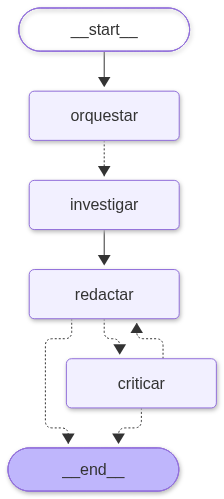

In [15]:
def construir_grafo_multi(cfg: Config):
    llm_orq = crear_llm(cfg.modelo_orquestador, "orquestador", json_mode=True, max_tokens=600)
    llm_red = crear_llm(cfg.modelo_redactor, "redactor", max_tokens=600)
    llm_crit = crear_llm(cfg.modelo_orquestador, "critico", json_mode=True, max_tokens=600)
    investigadores = {i: construir_agente_react(f"investigador_{i}", cfg.modelo_trabajador,
                                                INSTR_INVESTIGADOR.format(palabras=cfg.palabras_resumen), max_pasos=3)
                      for i in range(1, cfg.max_subtareas + 1)}

    async def orquestar(state: EstadoMulti, config: RunnableConfig):
        try:
            r = await llm_orq.ainvoke([SystemMessage(INSTR_ORQUESTADOR.format(n=cfg.max_subtareas)),
                                       HumanMessage(state["pregunta"])], config)
            subtareas = parsear_json(texto(r), Plan).subtareas[:cfg.max_subtareas] or [state["pregunta"]]
        except PresupuestoExcedido:
            raise
        except Exception:                      # salida cortada o inválida: una sola subtarea
            subtareas = [state["pregunta"]]
        return {"subtareas": subtareas, "rondas": 0, "comentarios": "", "notas": []}

    def repartir(state: EstadoMulti):
        # Send = un nodo 'investigar' por subtarea, todos en paralelo
        return [Send("investigar", {"pregunta": state["pregunta"], "subtarea": st, "indice": i})
                for i, st in enumerate(state["subtareas"], 1)]

    async def investigar(entrada: EntradaInvestigador, config: RunnableConfig):
        agente = investigadores[entrada["indice"]]
        salida = await agente.ainvoke({"messages": [HumanMessage(
            f"Pregunta general: {entrada['pregunta']}\nTu subtarea: {entrada['subtarea']}")]}, config)
        return {"notas": [(entrada["subtarea"], texto(salida["messages"][-1]))]}

    def contexto(state: EstadoMulti) -> str:
        notas = "\n\n".join(f"### {st}\n{nota}" for st, nota in state["notas"])
        return f"Pregunta: {state['pregunta']}\n\nNotas:\n{notas}"

    async def redactar(state: EstadoMulti, config: RunnableConfig):
        entrada = contexto(state)
        if state.get("comentarios"):
            entrada += f"\n\nBorrador anterior:\n{state['borrador']}\n\nComentarios del crítico:\n{state['comentarios']}"
        r = await llm_red.ainvoke([SystemMessage(INSTR_REDACTOR), HumanMessage(entrada)], config)
        return {"borrador": texto(r)}

    async def criticar(state: EstadoMulti, config: RunnableConfig):
        try:
            r = await llm_crit.ainvoke([SystemMessage(INSTR_CRITICO),
                                        HumanMessage(f"{contexto(state)}\n\nRespuesta propuesta:\n{state['borrador']}")], config)
            ev = parsear_json(texto(r), Evaluacion)
        except PresupuestoExcedido:
            raise
        except Exception:                      # salida cortada o inválida: se toma como aprobada
            return {"aprobado": True, "comentarios": "", "rondas": state["rondas"] + 1}
        return {"aprobado": ev.aprobado, "comentarios": "" if ev.aprobado else ev.comentarios,
                "rondas": state["rondas"] + 1}

    def tras_redactar(state: EstadoMulti):
        return "criticar" if state["rondas"] < cfg.max_rondas_critico else END

    def tras_criticar(state: EstadoMulti):
        return END if state["aprobado"] else "redactar"

    g = StateGraph(EstadoMulti)
    g.add_node("orquestar", orquestar)
    g.add_node("investigar", investigar)
    g.add_node("redactar", redactar)
    g.add_node("criticar", criticar)
    g.add_edge(START, "orquestar")
    g.add_conditional_edges("orquestar", repartir, ["investigar"])
    g.add_edge("investigar", "redactar")          # espera a que terminen todos los investigadores
    g.add_conditional_edges("redactar", tras_redactar, ["criticar", END])
    g.add_conditional_edges("criticar", tras_criticar, ["redactar", END])
    return g.compile(name="multiagente")

CONSTRUCTORES["multi"] = construir_grafo_multi

CFG_MULTI = Config("B · multiagente barato", "multi")
mostrar_grafo(grafo_de(CFG_MULTI))

### 5.3 Ejecución paso a paso

`astream(..., stream_mode="updates")` emite un evento cada vez que un nodo termina. Sirve para ver el recorrido del grafo: el orquestador, los investigadores en paralelo, el redactor y las rondas del crítico.

In [16]:
tarea_demo = uuid.uuid4().hex[:8]
async for evento in grafo_de(CFG_MULTI).astream({"pregunta": PREGUNTA_DEMO}, config_tarea(CFG_MULTI, tarea_demo),
                                                 stream_mode="updates"):
    for nodo, cambios in evento.items():
        claves = ", ".join(cambios.keys()) if cambios else "-"
        print(f"{nodo:<12} actualizó: {claves}")

orquestar    actualizó: subtareas, rondas, comentarios, notas


investigar   actualizó: notas


investigar   actualizó: notas


investigar   actualizó: notas


redactar     actualizó: borrador


criticar     actualizó: aprobado, comentarios, rondas


In [17]:
r_multi = await ejecutar_tarea(CFG_MULTI, PREGUNTA_DEMO)
print(r_multi["respuesta"], "\n")
print(f"Costo: USD {r_multi['costo_usd']:.5f} · latencia {r_multi['latencia_s']:.2f} s · éxito {r_multi['exito']}")

La opción que conviene más es la **Opción A (tienda online con suscripciones)**, porque es la única con punto de equilibrio documentado dentro del umbral exigido: inversión de COP 95 millones y recuperación estimada en 14 meses [D7]. La Opción B requiere COP 420 millones, arriendo mensual de COP 11 millones y alcanza el punto de equilibrio en 30 meses, por lo que no cumple el requisito de <24 meses [D8]. La Opción C implica una inversión menor (COP 60 millones) y un margen de 24 %, pero el corpus no reporta su punto de equilibrio [D9]; además, la certificación sanitaria con 6 meses de trámite retrasa el inicio de ingresos [D9], lo que añade incertidumbre al plazo de recuperación. Solo la Opción A tiene punto de equilibrio documentado dentro de 24 meses [D7].

**Recomendación explícita:** aprobar la Opción A, dado que su recuperación estimada de 14 meses [D7] cumple la exigencia de la junta; conviene además monitorear los riesgos transversales (concentración en clientes B2B y volatilida

## 6. Observabilidad

Con las trazas del `Trazador` se responde **dónde se va el dinero y el tiempo**:

1. **Costo por rol** de una tarea.
2. **Línea de tiempo** (Gantt): qué corrió en paralelo y cuál es la ruta crítica.
3. **Indicadores de coordinación**: qué parte del costo se va en coordinar (orquestador, crítico, router) y cuántas consultas se repitieron.

,llamadas,tokens_entrada,tokens_salida,costo_usd,% costo
rol,,,,,
investigador,7,5419,1220,0.000740,55.9
critico,1,1326,81,0.000347,26.2
redactor,1,999,290,0.000172,13.0
orquestador,1,118,90,0.000066,5.0


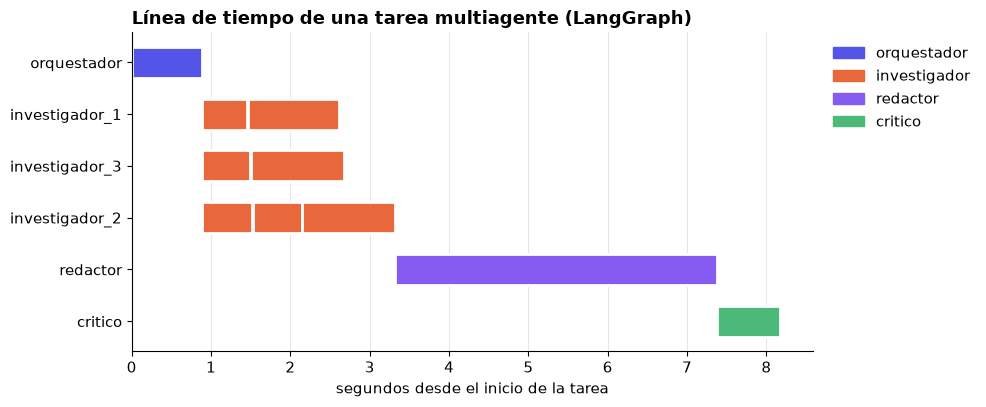

In [18]:
# Paleta institucional Icesi (validada para daltonismo en este orden)
COLORES_ROL = {"orquestador": "#5454e9", "investigador": "#e9683b", "redactor": "#865cf0",
               "critico": "#4cb979", "unico": "#5454e9", "router": "#865cf0", "juez": "#88898c"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})

def costo_por_rol(tarea: str) -> pd.DataFrame:
    df = trazas_df()
    df = df[df["tarea"] == tarea]
    t = df.groupby("rol").agg(llamadas=("agente", "size"), tokens_entrada=("tokens_entrada", "sum"),
                             tokens_salida=("tokens_salida", "sum"), costo_usd=("costo_usd", "sum"))
    t["% costo"] = (100 * t["costo_usd"] / t["costo_usd"].sum()).round(1)
    return t.sort_values("costo_usd", ascending=False)

def grafica_gantt(tarea: str, titulo: str):
    df = trazas_df()
    df = df[df["tarea"] == tarea].copy()
    t0 = df["inicio"].min()
    df["ini"], df["dur"] = df["inicio"] - t0, df["fin"] - df["inicio"]
    agentes = list(dict.fromkeys(df["agente"]))
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(agentes) + 1.2))
    for _, f in df.iterrows():
        ax.barh(agentes.index(f["agente"]), f["dur"], left=f["ini"], height=0.6,
                color=COLORES_ROL.get(f["rol"], "#5454e9"), edgecolor="white", linewidth=2)
    ax.set_yticks(range(len(agentes)), agentes)
    ax.invert_yaxis()
    ax.set_xlabel("segundos desde el inicio de la tarea")
    ax.set_title(titulo)
    roles = list(dict.fromkeys(df["rol"]))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORES_ROL[r]) for r in roles], labels=roles,
              loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

display(costo_por_rol(r_multi["tarea"]))
grafica_gantt(r_multi["tarea"], "Línea de tiempo de una tarea multiagente (LangGraph)")

In [19]:
def indicadores_coordinacion(tarea: str, docs: list[str]) -> dict:
    df = trazas_df()
    df = df[df["tarea"] == tarea]
    total = df["costo_usd"].sum() or 1e-12
    coord = df[df["rol"].isin(["orquestador", "critico", "router"])]["costo_usd"].sum()
    repetidos = len(docs) - len(set(docs))
    return {"llamadas": len(df),
            "% costo en coordinación": round(100 * coord / total, 1),
            "documentos consultados": len(docs),
            "% consultas repetidas": round(100 * repetidos / max(1, len(docs)), 1)}

pd.DataFrame({"A · agente único": indicadores_coordinacion(r_unico["tarea"], r_unico["docs"]),
              "B · multiagente": indicadores_coordinacion(r_multi["tarea"], r_multi["docs"])})

,A · agente único,B · multiagente
llamadas,2.0,10.0
% costo en coordinación,0.0,31.2
documentos consultados,6.0,19.0
% consultas repetidas,33.3,68.4


## 7. Evaluación

Ocho preguntas, cada una con sus **puntos clave esperados**, y un **juez LLM** de otra familia que califica con una rúbrica:

| Criterio | Escala | Peso |
|---|---|---|
| Cobertura de puntos clave | fracción de puntos presentes | 60 % |
| Fidelidad (sin cifras inventadas, con citas) | 1 a 5 | 25 % |
| Claridad y recomendación explícita | 1 a 5 | 15 % |

El costo del juez se registra con `config = "juez"` para no mezclarlo con el del sistema evaluado.

In [20]:
DATASET = [
    {"pregunta": "¿Qué opción de expansión conviene más si la junta exige recuperar la inversión en menos de 24 meses?",
     "puntos": [{"texto": "La tienda online recupera la inversión en 14 meses", "termino": "14 meses"},
                {"texto": "La segunda tienda tarda 30 meses, por encima del límite", "termino": "30 meses"},
                {"texto": "La junta exige menos de 24 meses", "termino": "24 meses"},
                {"texto": "La tienda online requiere COP 95 millones", "termino": "95"}]},
    {"pregunta": "¿Qué canal de venta crece más y cuál deja mejor margen?",
     "puntos": [{"texto": "Domicilios por WhatsApp creció 41 %", "termino": "41"},
                {"texto": "La tienda tiene el mayor margen, 58 %", "termino": "58"},
                {"texto": "B2B tiene el menor margen, 31 %", "termino": "31"}]},
    {"pregunta": "¿La capacidad de la planta alcanza para la exportación a Chile?",
     "puntos": [{"texto": "El pedido mínimo es 1,2 toneladas al año", "termino": "1,2"},
                {"texto": "La planta trabaja al 72 % en un turno", "termino": "72"},
                {"texto": "Un segundo turno aumenta la capacidad 60 %", "termino": "60"},
                {"texto": "Se requiere certificación sanitaria de 6 meses", "termino": "certificacion"}]},
    {"pregunta": "¿Qué riesgos financieros y operativos enfrenta la empresa?",
     "puntos": [{"texto": "Tres clientes B2B concentran el 29 % de las ventas", "termino": "29"},
                {"texto": "La rotación de baristas es 35 % anual", "termino": "35"},
                {"texto": "El café verde subió 22 % en 2025", "termino": "22"}]},
    {"pregunta": "¿Hay evidencia de demanda para un modelo de suscripción?",
     "puntos": [{"texto": "El 63 % compraría una suscripción", "termino": "63"},
                {"texto": "Dos competidores ya venden con suscripción", "termino": "suscripcion"},
                {"texto": "Los domicilios tardan 3,2 días, principal queja", "termino": "3,2"}]},
    {"pregunta": "¿Puede la empresa financiar la segunda tienda sin crédito?",
     "puntos": [{"texto": "La segunda tienda cuesta COP 420 millones", "termino": "420"},
                {"texto": "La caja disponible es COP 380 millones: no alcanza", "termino": "380"},
                {"texto": "Hay un crédito preaprobado de COP 250 millones al 17 %", "termino": "17"}]},
    {"pregunta": "¿Cómo afecta el precio del café verde la rentabilidad del canal B2B?",
     "puntos": [{"texto": "El café verde es el 46 % del costo de producción", "termino": "46"},
                {"texto": "Su precio subió 22 % en 2025", "termino": "22"},
                {"texto": "B2B tiene margen de 31 % y precios fijos anuales", "termino": "31"}]},
    {"pregunta": "¿Qué debería mejorar primero en domicilios antes de lanzar una tienda online?",
     "puntos": [{"texto": "El tiempo de entrega promedio es 3,2 días", "termino": "3,2"},
                {"texto": "El margen de domicilios es 44 % después de envío", "termino": "44"},
                {"texto": "La tienda online requiere una persona de atención", "termino": "persona"}]},
]

INSTR_JUEZ = """Eres un evaluador estricto e imparcial. Compara la respuesta con los puntos clave esperados.
Para cada punto clave, en el mismo orden, indica si la respuesta lo contiene con el mismo dato (true/false).
Califica fidelidad de 1 a 5 (5 = toda cifra está respaldada y citada; 1 = hay cifras inventadas)
y claridad de 1 a 5 (5 = clara, breve y con una recomendación explícita).
Responde solo con un objeto JSON que incluya SIEMPRE estas cuatro claves, todas obligatorias:
{"puntos_presentes": [true, false, ...], "fidelidad": <entero 1-5>, "claridad": <entero 1-5>, "justificacion": "<máximo 30 palabras>"}"""
class Juicio(BaseModel):
    puntos_presentes: list[bool]
    fidelidad: int
    claridad: int
    justificacion: str = ""

LLM_JUEZ = crear_llm(MODELOS["juez"], "juez", json_mode=True, max_tokens=1000)

ERRORES_JUEZ: list[str] = []

async def juzgar(item: dict, respuesta: str) -> dict:
    if not respuesta:
        return {"cobertura": 0.0, "fidelidad": 1, "claridad": 1, "calidad": 0.0}
    entrada = (f"Pregunta: {item['pregunta']}\n<puntos>{json.dumps(item['puntos'], ensure_ascii=False)}</puntos>\n"
               f"<respuesta>{respuesta}</respuesta>")
    config = {"callbacks": [TRAZADOR], "metadata": {"tarea": "juez-" + uuid.uuid4().hex[:6], "config": "juez"}}
    try:
        j = parsear_json(texto(await LLM_JUEZ.ainvoke([SystemMessage(INSTR_JUEZ), HumanMessage(entrada)], config)), Juicio)
    except Exception as e:                     # juicio cortado o inválido: queda nulo y se cuenta en 'juicios fallidos'
        ERRORES_JUEZ.append(repr(e)[:300])
        return {"cobertura": None, "fidelidad": None, "claridad": None, "calidad": None}
    presentes = (j.puntos_presentes + [False] * len(item["puntos"]))[:len(item["puntos"])]
    cobertura = sum(presentes) / len(item["puntos"])
    calidad = 0.60 * cobertura + 0.25 * (j.fidelidad - 1) / 4 + 0.15 * (j.claridad - 1) / 4
    return {"cobertura": cobertura, "fidelidad": j.fidelidad, "claridad": j.claridad, "calidad": round(calidad, 3)}

In [21]:
SEM_TAREAS = asyncio.Semaphore(TAREAS_SIMULTANEAS)

async def _tarea_limitada(cfg, pregunta):
    async with SEM_TAREAS:
        return await ejecutar_tarea(cfg, pregunta)

async def evaluar(cfg: Config, dataset=DATASET, repeticiones: int = REPETICIONES) -> pd.DataFrame:
    items = [it for it in dataset for _ in range(repeticiones)]
    resultados = await asyncio.gather(*[_tarea_limitada(cfg, it["pregunta"]) for it in items])
    juicios = await asyncio.gather(*[juzgar(it, r["respuesta"]) for it, r in zip(items, resultados)])
    tr = trazas_df()
    filas = []
    for r, j in zip(resultados, juicios):
        ind = indicadores_coordinacion(r["tarea"], r["docs"])
        t = tr[tr["tarea"] == r["tarea"]]
        filas.append({**{k: r[k] for k in ("tarea", "config", "pregunta", "exito", "latencia_s", "costo_usd")}, **j,
                      "llamadas": ind["llamadas"], "tokens": int(t["tokens_entrada"].sum() + t["tokens_salida"].sum()),
                      "pct_coordinacion": ind["% costo en coordinación"], "pct_repetidas": ind["% consultas repetidas"]})
    return pd.DataFrame(filas)

def resumen(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby("config", sort=False)
    return pd.DataFrame({
        "calidad (0-1)": g["calidad"].mean().round(3),
        "± desv. calidad": g["calidad"].std().round(3),
        "tareas": g.size(),
        "juicios fallidos": g["calidad"].apply(lambda x: int(x.isna().sum())),
        "cobertura": g["cobertura"].mean().round(2),
        "éxito %": (100 * g["exito"].mean()).round(0),
        "costo medio USD": g["costo_usd"].mean().round(5),
        "USD por 1.000 tareas": (1000 * g["costo_usd"].mean()).round(2),
        "latencia p50 s": g["latencia_s"].median().round(2),
        "latencia p95 s": g["latencia_s"].quantile(0.95).round(2),
        "llamadas": g["llamadas"].mean().round(1),
        "tokens": g["tokens"].mean().round(0),
        "% costo coordinación": g["pct_coordinacion"].mean().round(1),
        "% consultas repetidas": g["pct_repetidas"].mean().round(1),
    })

## 8. Experimento comparativo

- **A · agente único** con el modelo barato (baseline).
- **B · multiagente barato**: todos los roles con el modelo barato.
- **C · multiagente mixto**: orquestador, crítico y redactor con el modelo fuerte; investigadores con el barato.

Con modelos reales conviene `repeticiones=2` o más: las respuestas varían entre ejecuciones.

In [22]:
CFG_MIXTO = Config("C · multiagente mixto", "multi", modelo_orquestador=MODELOS["fuerte"], modelo_redactor=MODELOS["fuerte"])
EXPERIMENTO = [CFG_UNICO, CFG_MULTI, CFG_MIXTO]

resultados = pd.concat([await evaluar(cfg) for cfg in EXPERIMENTO], ignore_index=True)
tabla = resumen(resultados)
tabla

,calidad (0-1),± desv. calidad,tareas,juicios fallidos,cobertura,éxito %,costo medio USD,USD por 1.000 tareas,latencia p50 s,latencia p95 s,llamadas,tokens,% costo coordinación,% consultas repetidas
config,,,,,,,,,,,,,,
A · agente único,0.905,0.108,24,0,0.95,100.0,0.00027,0.27,2.41,3.75,2.1,1951.0,0.0,33.3
B · multiagente barato,0.853,0.133,24,0,0.88,100.0,0.00157,1.57,7.20,10.14,9.2,8998.0,21.3,70.6
C · multiagente mixto,0.821,0.145,24,0,0.86,100.0,0.00545,5.45,13.88,25.45,10.0,9634.0,40.1,66.4


### Frontera de Pareto: costo contra calidad

Una configuración está en la frontera si ninguna otra es a la vez más barata y de mejor calidad.

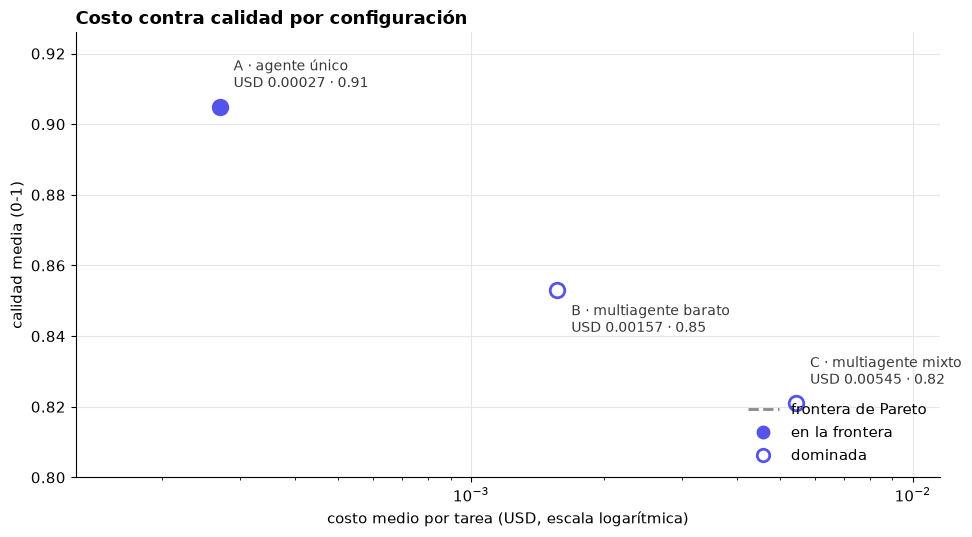

In [23]:
def frontera_pareto(tabla: pd.DataFrame) -> list[str]:
    puntos = tabla[["costo medio USD", "calidad (0-1)"]]
    return [n for n, (c, q) in puntos.iterrows()
            if not any((c2 <= c and q2 >= q) and (c2 < c or q2 > q) for c2, q2 in puntos.values)]

def grafica_pareto(tabla: pd.DataFrame, titulo="Costo contra calidad por configuración"):
    frontera = frontera_pareto(tabla)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    f = tabla.loc[frontera].sort_values("costo medio USD")
    ax.plot(f["costo medio USD"], f["calidad (0-1)"], color="#88898c", linewidth=2, linestyle="--", zorder=1)
    orden = tabla.sort_values("costo medio USD")
    for k, (nombre, fila) in enumerate(orden.iterrows()):
        en_frontera = nombre in frontera
        ax.scatter(fila["costo medio USD"], fila["calidad (0-1)"], s=110, zorder=2,
                   color="#5454e9" if en_frontera else "white", edgecolor="#5454e9", linewidth=2)
        ax.annotate(f"{nombre}\nUSD {fila['costo medio USD']:.5f} · {fila['calidad (0-1)']:.2f}",
                    (fila["costo medio USD"], fila["calidad (0-1)"]), textcoords="offset points",
                    xytext=(10, 14 if k % 2 == 0 else -30), fontsize=10, color="#393939")
    ax.set_xscale("log")   # los costos difieren en órdenes de magnitud
    ax.set_xlabel("costo medio por tarea (USD, escala logarítmica)")
    ax.set_ylabel("calidad media (0-1)")
    ax.set_title(titulo)
    ax.margins(x=0.25, y=0.25)
    ax.legend(handles=[plt.Line2D([], [], color="#88898c", linestyle="--", linewidth=2),
                       plt.Line2D([], [], marker="o", color="#5454e9", linestyle="", markersize=9),
                       plt.Line2D([], [], marker="o", markerfacecolor="white", markeredgecolor="#5454e9",
                                  markeredgewidth=2, linestyle="", markersize=9)],
              labels=["frontera de Pareto", "en la frontera", "dominada"],
              frameon=False, loc="lower right")
    plt.tight_layout()
    plt.show()
    return frontera
_ = grafica_pareto(tabla)

En modo simulado es normal que el agente único quede igual o mejor que el multiagente: el simulador no razona, solo copia documentos. Con modelos reales el resultado puede cambiar; la arquitectura se elige con datos, no por intuición.

In [24]:
resultados.pivot_table(index="pregunta", columns="config", values="calidad", sort=False).round(2)

config,A · agente único,B · multiagente barato,C · multiagente mixto
pregunta,,,
¿Qué opción de expansión conviene más si la junta exige recuperar la inversión en menos de 24 meses?,0.96,0.94,0.84
¿Qué canal de venta crece más y cuál deja mejor margen?,0.90,0.91,0.91
¿La capacidad de la planta alcanza para la exportación a Chile?,0.84,0.78,0.77
¿Qué riesgos financieros y operativos enfrenta la empresa?,0.98,0.90,0.93
¿Hay evidencia de demanda para un modelo de suscripción?,1.00,0.95,0.88
¿Puede la empresa financiar la segunda tienda sin crédito?,0.92,0.76,0.70
¿Cómo afecta el precio del café verde la rentabilidad del canal B2B?,0.92,0.93,0.94
¿Qué debería mejorar primero en domicilios antes de lanzar una tienda online?,0.70,0.66,0.60


## 9. Optimización y router

| Palanca | Qué hace | Dónde |
|---|---|---|
| Compresión de contexto | resúmenes más cortos de los investigadores | `palabras_resumen` |
| Parada temprana | menos rondas del crítico | `max_rondas_critico` |
| Menos paralelismo | menos subtareas | `max_subtareas` |
| Enrutamiento | preguntas simples al agente único, complejas al equipo | grafo `router` |
| Caché de prompts | prefijos repetidos más baratos | columna `tokens_cache` |

El **router** es otro patrón de la clase y en LangGraph es natural: un nodo clasifica y una arista condicional elige el camino. Los grafos del agente único y del equipo se reutilizan como **subgrafos**.

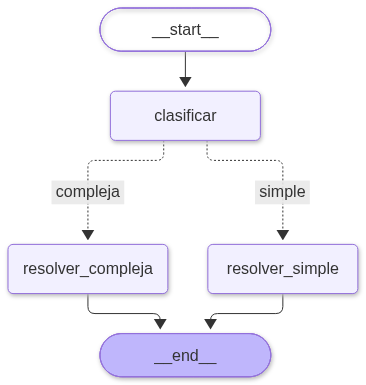

In [25]:
INSTR_ROUTER = """Clasifica la pregunta según cuánta evidencia requiere.
"simple": se responde con uno o dos documentos de un mismo tema.
"compleja": requiere combinar varios temas (finanzas, operación, clientes, riesgos).
Responde solo con JSON: {"complejidad": "simple"} o {"complejidad": "compleja"}"""
class Ruta(BaseModel):
    complejidad: str

class EstadoRouter(TypedDict, total=False):
    pregunta: str
    ruta: str
    respuesta: str

def construir_grafo_router(cfg: Config):
    llm_router = crear_llm(cfg.modelo_trabajador, "router", json_mode=True, max_tokens=150)
    unico, multi = construir_grafo_unico(cfg), construir_grafo_multi(cfg)

    async def clasificar(state: EstadoRouter, config: RunnableConfig):
        try:
            r = await llm_router.ainvoke([SystemMessage(INSTR_ROUTER), HumanMessage(state["pregunta"])], config)
            ruta = parsear_json(texto(r), Ruta).complejidad
        except PresupuestoExcedido:
            raise
        except Exception:                      # salida cortada o inválida: ante la duda, el equipo completo
            ruta = "compleja"
        return {"ruta": ruta if ruta in ("simple", "compleja") else "compleja"}

    async def resolver_simple(state: EstadoRouter, config: RunnableConfig):
        s = await unico.ainvoke({"messages": [HumanMessage(state["pregunta"])]}, config)
        return {"respuesta": texto(s["messages"][-1])}

    async def resolver_compleja(state: EstadoRouter, config: RunnableConfig):
        s = await multi.ainvoke({"pregunta": state["pregunta"]}, config)
        return {"respuesta": s["borrador"]}

    g = StateGraph(EstadoRouter)
    g.add_node("clasificar", clasificar)
    g.add_node("resolver_simple", resolver_simple)
    g.add_node("resolver_compleja", resolver_compleja)
    g.add_edge(START, "clasificar")
    g.add_conditional_edges("clasificar", lambda s: s["ruta"],
                            {"simple": "resolver_simple", "compleja": "resolver_compleja"})
    g.add_edge("resolver_simple", END)
    g.add_edge("resolver_compleja", END)
    return g.compile(name="router")

CONSTRUCTORES["router"] = construir_grafo_router

CFG_OPTIMIZADO = Config("D · multiagente optimizado", "multi", max_subtareas=2, max_rondas_critico=1, palabras_resumen=80)
CFG_ROUTER = Config("E · router", "router", max_subtareas=2, max_rondas_critico=1, palabras_resumen=80)
mostrar_grafo(grafo_de(CFG_ROUTER))

In [26]:
optim = pd.concat([await evaluar(cfg) for cfg in (CFG_OPTIMIZADO, CFG_ROUTER)], ignore_index=True)
resultados = pd.concat([resultados, optim], ignore_index=True)
tabla = resumen(resultados)
tabla

,calidad (0-1),± desv. calidad,tareas,juicios fallidos,cobertura,éxito %,costo medio USD,USD por 1.000 tareas,latencia p50 s,latencia p95 s,llamadas,tokens,% costo coordinación,% consultas repetidas
config,,,,,,,,,,,,,,
A · agente único,0.905,0.108,24,0,0.95,100.0,0.00027,0.27,2.41,3.75,2.1,1951.0,0.0,33.3
B · multiagente barato,0.853,0.133,24,0,0.88,100.0,0.00157,1.57,7.20,10.14,9.2,8998.0,21.3,70.6
C · multiagente mixto,0.821,0.145,24,0,0.86,100.0,0.00545,5.45,13.88,25.45,10.0,9634.0,40.1,66.4
D · multiagente optimizado,0.850,0.139,24,0,0.89,100.0,0.00112,1.12,6.43,17.54,7.2,6029.0,22.1,56.9
E · router,0.847,0.158,24,0,0.89,100.0,0.00110,1.10,6.12,13.85,8.2,5959.0,21.3,57.9


,Δ costo %,Δ calidad (puntos),Δ latencia p50 %
D · multiagente optimizado,-28.7,-0.003,-10.7
E · router,-29.9,-0.006,-15.0


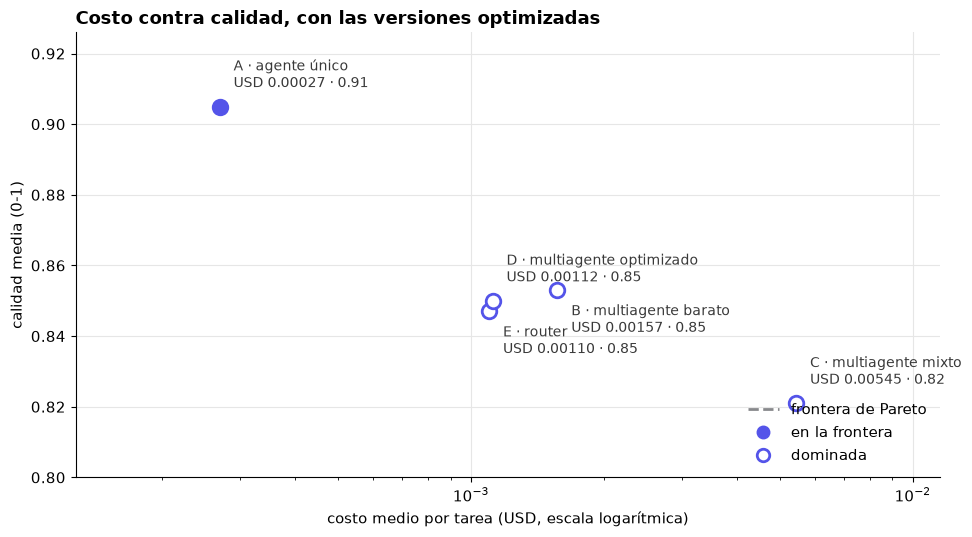

In [27]:
base = tabla.loc["B · multiagente barato"]
comparacion = pd.DataFrame({
    nombre: {"Δ costo %": round(100 * (tabla.loc[nombre, "costo medio USD"] / base["costo medio USD"] - 1), 1),
             "Δ calidad (puntos)": round(tabla.loc[nombre, "calidad (0-1)"] - base["calidad (0-1)"], 3),
             "Δ latencia p50 %": round(100 * (tabla.loc[nombre, "latencia p50 s"] / base["latencia p50 s"] - 1), 1)}
    for nombre in ["D · multiagente optimizado", "E · router"]}).T
display(comparacion)
_ = grafica_pareto(tabla, "Costo contra calidad, con las versiones optimizadas")

### Caché de prompts

Muchos proveedores cobran menos por los tokens de entrada que repiten un prefijo ya visto (DeepSeek lo hace automáticamente). Lo **fijo** (instrucciones, herramientas) va al inicio y lo **variable** al final. LangChain reporta lo reutilizado en `usage_metadata.input_token_details.cache_read`, que aquí aparece como `tokens_cache`. En modo simulado siempre es cero.

In [28]:
tr = trazas_df()
tr = tr[tr["config"].notna() & (tr["config"] != "juez")]
cache = tr.groupby("config", sort=False)[["tokens_entrada", "tokens_cache"]].sum()
cache["% entrada en caché"] = (100 * cache["tokens_cache"] / cache["tokens_entrada"].clip(lower=1)).round(1)
cache

,tokens_entrada,tokens_cache,% entrada en caché
config,,,
A · agente único,38384,20608,53.7
B · multiagente barato,193211,61476,31.8
C · multiagente mixto,189763,65328,34.4
D · multiagente optimizado,118894,35078,29.5
E · router,117438,35200,30.0


### Costo total de la sesión

Incluye al juez y a la ejecución de demostración con `astream`.

In [29]:
tr = trazas_df()
total = tr.groupby(tr["config"].fillna("sin config"))["costo_usd"].agg(["count", "sum"]).rename(
    columns={"count": "llamadas", "sum": "USD"})
total.loc["TOTAL"] = total.sum()
print("Modo:", "SIMULADO (costos estimados con la tabla de precios)" if MODO_SIMULADO else "OpenRouter (costos reales)")
total.round(5)

Modo: OpenRouter (costos reales)


,llamadas,USD
config,,
A · agente único,52,0.00672
B · multiagente barato,242,0.04036
C · multiagente mixto,240,0.13087
D · multiagente optimizado,174,0.02678
E · router,196,0.02638
juez,120,0.01825
TOTAL,1024,0.24938


In [30]:
resultados.to_csv("resultados_langgraph.csv", index=False)
trazas_df().to_csv("trazas_langgraph.csv", index=False)
print("Archivos guardados: resultados_langgraph.csv, trazas_langgraph.csv")

Archivos guardados: resultados_langgraph.csv, trazas_langgraph.csv


## 10. Ejercicios

1. **Verificador de hechos.** Agregar un nodo `verificar` entre `redactar` y `criticar` que compare cada cifra con el documento citado. ¿Cuánto sube la fidelidad y cuánto cuesta?
2. **Pipeline fijo.** Reemplazar `Send` por una cadena de aristas fijas (ventas → costos → riesgos → redactar). ¿Qué pasa con la latencia?
3. **Reto de costo.** Lograr una configuración que cueste al menos 40 % menos que B sin perder más de 0,05 de calidad.
4. **Humano en el bucle.** Compilar el grafo con un `checkpointer` (`MemorySaver`) e `interrupt_before=["redactar"]` para revisar las notas antes de redactar. ¿Qué cambia en el diseño?
5. **Prebuilt.** Reemplazar `construir_agente_react` por el agente prefabricado de LangGraph. ¿Cambian las trazas o el costo?
6. **Comparación de versiones.** Correr el mismo experimento en el notebook sin frameworks. ¿Coinciden costo y calidad? ¿Qué aporta LangGraph y qué oculta?